In [1]:
import os
import torch
import torch.nn as nn
import json

from config import get_config
from train_utils.gpu_utils import get_device_summary
from data.loader import get_dataloaders
from models.model import create_model
from train_utils.resume import init_resume_state
from train_utils.resume import fill_trackers_from_history
from train_utils.resume import load_pretrained_model
from train_utils.training_loop import run_training_loop
from train_utils.scheduler_utils import create_scheduler
from train_utils.training_summary import finalize_training_summary
from train_utils.training_summary import print_best_model_summary
from train_utils.plot_metrics import plot_train_val_metrics
from train_utils.plot_metrics import plot_loss_accuracy
from train_utils.plot_metrics import plot_confusion_matrices


In [2]:
# cfg=get_config(config_path="experiments/exp_02_transfer_learning_with_vit_backbone/config/" \
# "vit_tiny_patch16_224_gaussian_bs32_ep1_lr1e-04_p12_ds7200000_g500_sched-RLRP_preload_p4.yml")

cfg=get_config()
print(json.dumps(vars(cfg), indent=2))

[INFO] Config Path: experiments/exp_02_transfer_learning_with_vit_backbone/config/vit_tiny_patch16_224_gaussian_bs32_ep1_lr1e-04_p12_ds7200000_g500_sched-RLRP_preload_p4.yml
[INFO] Detected native Mint host: DS028160
[INFO] Using dataset root: /mnt/Research/arsalan/wsu_grid_rs_grp_mljet/ml-jet-ext/pTHat50-250_eCM5020_c0005_pT90-110_R0p4_agg500/
[INFO] Using dataset_size from config: 14000


In [3]:
os.makedirs(cfg.output_dir, exist_ok=True)
print(f"[INFO] Saving all outputs to: {cfg.output_dir}")

[INFO] Saving all outputs to: experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0


In [4]:
device= get_device_summary()

=== NVIDIA-SMI ===
Thu Feb  5 18:43:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.195.03             Driver Version: 570.195.03     CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4060 Ti     Off |   00000000:0B:00.0  On |                  N/A |
|  0%   44C    P5             13W /  165W |     592MiB /  16380MiB |     26%      Default |
|                                         |                        |                  N/A |
+----------------------------

In [5]:
# Data
train_loader, val_loader, test_loader = get_dataloaders(cfg, device=device)

[INFO] Training samples: 11200
[INFO] Validation samples: 2800
[INFO] Test samples: 2800
[INFO] Length of training dataloader: 350
[INFO] Length of validation dataloader: 88
[INFO] Length of test dataloader: 88


In [6]:
from models.model_vit_legacy import ViTClassifier
from models.model_vit_legacy_branch import ViTLegacyBranchedAdapter, load_legacy_checkpoint

legacy = ViTClassifier(input_shape=cfg.input_shape, pretrained=False, model_name="vit_tiny_patch16_224")
legacy = load_legacy_checkpoint(legacy, cfg.preload_model_path, map_location="cpu", strict=True)

model = ViTLegacyBranchedAdapter(
    legacy_model=legacy,
    alpha_classes=7,
    q0_classes=5,
    eloss_dim=1,
    branch_hidden_dim=128,
    branch_dropout=0.1,
    use_eloss_branch=True,
)

model.to(device)

# optimizer should see ONLY trainable params (branches)
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=cfg.learning_rate)

# quick checks
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen    = sum(p.numel() for p in model.parameters() if not p.requires_grad)
print("trainable params:", trainable)
print("frozen params:", frozen)


/home/arsalan/wsu-grid/ml-jet-ext/models/model_vit_legacy_branch.py:20: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(ckpt_path, map_location=map_location)

trainable params: 5133
frozen params: 5525960


In [15]:
# Model and optimizer
model, optimizer = create_model(cfg.backbone, cfg.input_shape, cfg.learning_rate,
                                       legacy_ckpt_path=cfg.preload_model_path,legacy_model_name='vit_tiny_patch16_224')
model.to(device)

ViTLegacyBranchedAdapter(
  (legacy): ViTClassifier(
    (backbone): VisionTransformer(
      (patch_embed): PatchEmbed(
        (proj): Conv2d(3, 192, kernel_size=(16, 16), stride=(16, 16))
        (norm): Identity()
      )
      (pos_drop): Dropout(p=0.0, inplace=False)
      (patch_drop): Identity()
      (norm_pre): Identity()
      (blocks): Sequential(
        (0): Block(
          (norm1): LayerNorm((192,), eps=1e-06, elementwise_affine=True)
          (attn): Attention(
            (qkv): Linear(in_features=192, out_features=576, bias=True)
            (q_norm): Identity()
            (k_norm): Identity()
            (attn_drop): Dropout(p=0.0, inplace=False)
            (proj): Linear(in_features=192, out_features=192, bias=True)
            (proj_drop): Dropout(p=0.0, inplace=False)
          )
          (ls1): Identity()
          (drop_path1): Identity()
          (norm2): LayerNorm((192,), eps=1e-06, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear

In [8]:
if torch.cuda.device_count() > 1:
    print(f"Parallelizing model across {torch.cuda.device_count()} GPUs")
    model = torch.nn.DataParallel(model)
elif torch.cuda.device_count() == 1:
    print("No parallelization, using single GPU")
elif torch.cuda.device_count() == 0:
    print("No GPU available, using CPU")

No parallelization, using single GPU


In [9]:
scheduler = create_scheduler(optimizer, cfg, train_loader=train_loader)

In [10]:
criterion = {
    # 'energy_loss_output': nn.BCELoss(),
    'energy_loss_output': nn.BCEWithLogitsLoss(),
    'alpha_output': nn.CrossEntropyLoss(),
    'q0_output': nn.CrossEntropyLoss()
}
print(f"[INFO] Loss functions:{criterion}")

[INFO] Loss functions:{'energy_loss_output': BCEWithLogitsLoss(), 'alpha_output': CrossEntropyLoss(), 'q0_output': CrossEntropyLoss()}


In [11]:
print(f"[INFO] Init Training Trackers")
train_loss_energy_list, train_loss_alpha_list, train_loss_q0_list, train_loss_list = [], [], [],[]
train_acc_energy_list, train_acc_alpha_list, train_acc_q0_list, train_acc_list = [], [], [], []

print(f"[INFO] Init Validation Trackers")
val_loss_energy_list, val_loss_alpha_list,val_loss_q0_list,val_loss_list = [], [], [], []
val_acc_energy_list, val_acc_alpha_list,val_acc_q0_list ,val_acc_list = [],[],[],[]

[INFO] Init Training Trackers
[INFO] Init Validation Trackers


In [12]:
model, optimizer, start_epoch, best_acc, early_stop_counter, best_epoch, best_metrics, training_summary, all_epoch_metrics,summary_status = init_resume_state( model, optimizer, device,cfg)

[INFO] Init Resume/Training Parameters
[INFO] Starting fresh training run by initializing training summary
[INFO] 📄 Training summary saved to: experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/training_summary.json


In [13]:
fill_trackers_from_history(
    all_epoch_metrics,
    train_loss_energy_list, train_loss_alpha_list, train_loss_q0_list, train_loss_list,
    train_acc_energy_list, train_acc_alpha_list, train_acc_q0_list, train_acc_list,
    val_loss_energy_list, val_loss_alpha_list, val_loss_q0_list, val_loss_list,
    val_acc_energy_list, val_acc_alpha_list, val_acc_q0_list, val_acc_list,
    summary_status, best_epoch
)

In [14]:
preload_path = getattr(cfg, "preload_model_path", None)
print(f"[INFO] Preloading model from: {preload_path}")


[INFO] Preloading model from: experiments/exp_preload_trained_model_and_train_more_best_model_so_far/training_output/ViT_tiny_patch16_224_gaussian_lrp_12_rlrp_4_bs32_ep50_lr1e-04_ds7200000_g500_sched_ReduceLROnPlateau_preloaded/last_model.pth


In [ ]:
# model, preloaded = load_pretrained_model(model, device, cfg)


In [ ]:
# for testing
# from train_utils.train_epoch import train_one_epoch
# train_metrics = train_one_epoch(train_loader, model, criterion, optimizer, device)
# print(f"[INFO] Training metrics: {train_metrics}")

In [16]:
best_epoch,best_acc,best_metrics=run_training_loop(
                      cfg,train_loader,val_loader,
                      device, model,criterion,
                      optimizer,scheduler,
                      start_epoch,early_stop_counter,
                      best_acc,best_metrics,best_epoch,
                      train_loss_list,
                        train_loss_energy_list,
                        train_loss_alpha_list,
                        train_loss_q0_list,
                        train_acc_list,
                        train_acc_energy_list,
                        train_acc_alpha_list,
                        train_acc_q0_list,
                        val_loss_list,
                        val_loss_energy_list,
                        val_loss_alpha_list,
                        val_loss_q0_list,
                        val_acc_list,
                        val_acc_energy_list,
                        val_acc_alpha_list,
                        val_acc_q0_list,
                        all_epoch_metrics)

[INFO] Epoch 1/1


[INFO] Epoch 1: Energy Acc =0.8000, αs Acc = 0.1429, Q0 Acc = 0.1896, Total Acc = 0.0246
[INFO] Epoch 1: Energy Loss =0.5023, αs Loss = 1.9563, Q0 Loss = 1.6107, Total Loss = 4.0693
📉 Current LR: 0.0001
[INFO] Epoch 1: Saving metrics to disk
💾 Last model saved at epoch 1
✅ Best model saved at epoch 1 with total accuracy: 0.0246


In [17]:
finalize_training_summary(
    summary=training_summary,
    best_epoch=best_epoch,
    best_acc=best_acc,
    best_metrics=best_metrics,
    output_dir=cfg.output_dir
)
print_best_model_summary(
    best_epoch=best_epoch,
    best_acc=best_acc,
    best_metrics=best_metrics
)

[INFO] 📄 Training summary saved to: experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/training_summary.json

🏁 Best Model @ Epoch 1
Total Accuracy: 0.0246

🔹 ENERGY Task
  Accuracy : 0.8000
  Precision: 0.4000
  Recall   : 0.5000
  F1-Score : 0.4444
  Confusion Matrix:
[[0, 560], [0, 2240]]

🔹 ALPHA Task
  Accuracy : 0.1429
  Precision: 0.0204
  Recall   : 0.1429
  F1-Score : 0.0357
  Confusion Matrix:
[[0, 0, 0, 0, 0, 0, 400], [0, 0, 0, 0, 0, 0, 400], [0, 0, 0, 0, 0, 0, 400], [0, 0, 0, 0, 0, 0, 400], [0, 0, 0, 0, 0, 0, 400], [0, 0, 0, 0, 0, 0, 400], [0, 0, 0, 0, 0, 0, 400]]

🔹 Q0 Task
  Accuracy : 0.1896
  Precision: 0.0758
  Recall   : 0.1896
  F1-Score : 0.1083
  Confusion Matrix:
[[0, 281, 279, 0, 0], [0, 243, 317, 0, 0], [0, 272, 288, 0, 0], [0, 281, 279, 0, 0], [0, 317, 243, 0, 0]]


📊 Plots saved to:
 - experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/loss_accuracy_plot.png
 - experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/loss_accuracy_plot.pdf


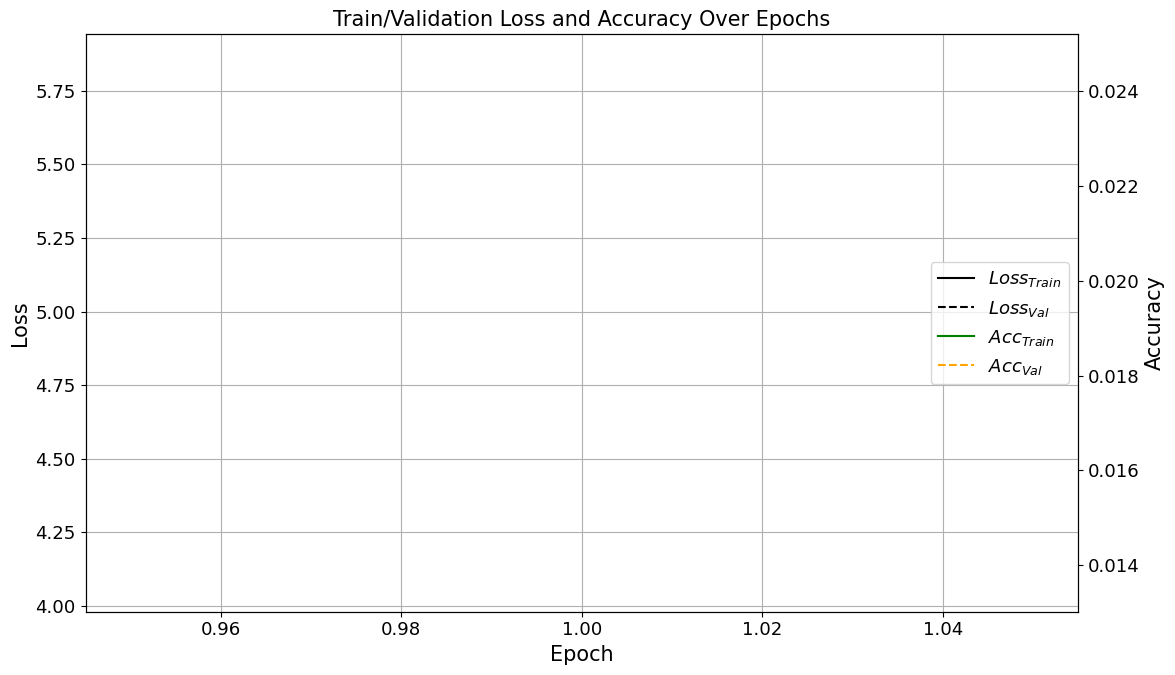

📉 Loss plot saved as:
  - experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/train_loss_and_accuracy_per_epoch_plot.png
  - experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/train_loss_and_accuracy_per_epoch_plot.pdf


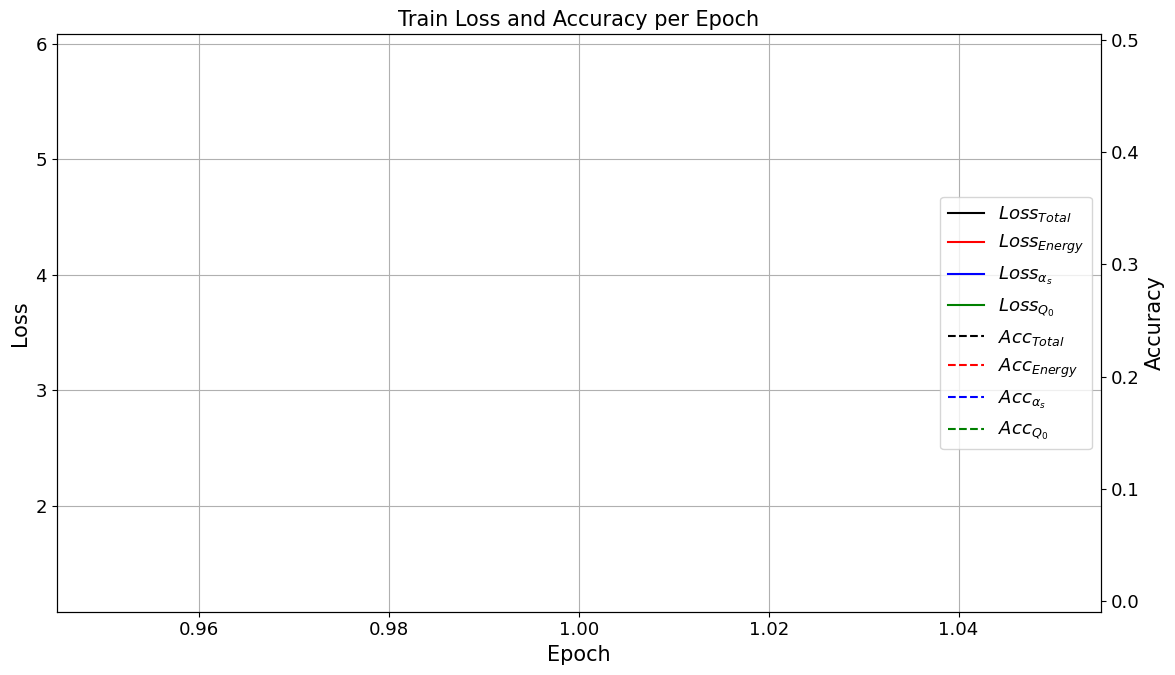

📉 Loss plot saved as:
  - experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/validation_loss_and_accuracy_per_epoch_plot.png
  - experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/validation_loss_and_accuracy_per_epoch_plot.pdf


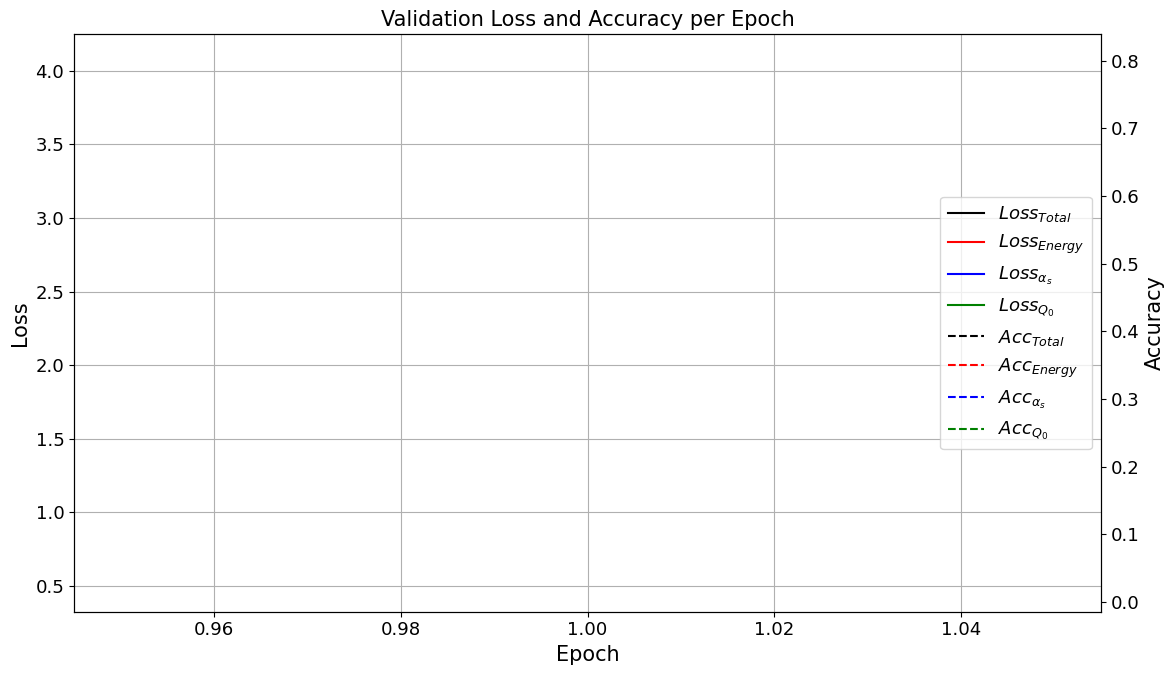

In [18]:
plot_train_val_metrics(train_loss_list, val_loss_list, train_acc_list, val_acc_list, cfg.output_dir)
plot_loss_accuracy(train_loss_list,
                    train_loss_energy_list,
                    train_loss_alpha_list,
                    train_loss_q0_list,
                    train_acc_list,
                    train_acc_energy_list,
                    train_acc_alpha_list,
                    train_acc_q0_list,
                    cfg.output_dir,
                    title="Train Loss and Accuracy per Epoch")
plot_loss_accuracy(val_loss_list,
                    val_loss_energy_list,
                    val_loss_alpha_list,
                    val_loss_q0_list,
                    val_acc_list,
                    val_acc_energy_list,
                    val_acc_alpha_list,
                    val_acc_q0_list,
                    cfg.output_dir,
                    title="Validation Loss and Accuracy per Epoch")

✅ Saved confusion matrix for energy:
 - experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/val/confusion_plots/confusion_matrix_energy.png
 - experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/val/confusion_plots/confusion_matrix_energy.pdf


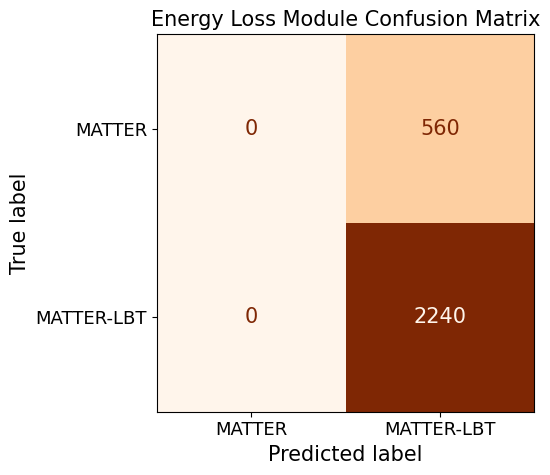

✅ Saved confusion matrix for alpha:
 - experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/val/confusion_plots/confusion_matrix_alpha.png
 - experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/val/confusion_plots/confusion_matrix_alpha.pdf


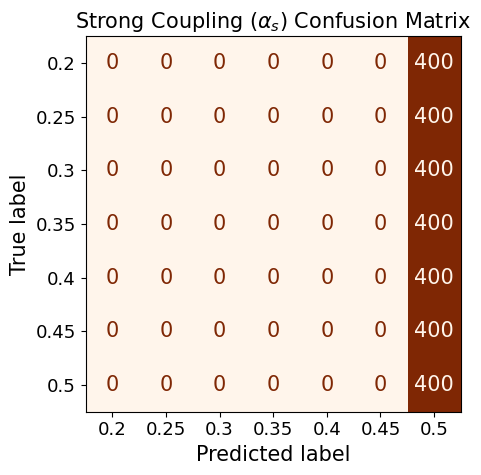

✅ Saved confusion matrix for q0:
 - experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/val/confusion_plots/confusion_matrix_q0.png
 - experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/val/confusion_plots/confusion_matrix_q0.pdf


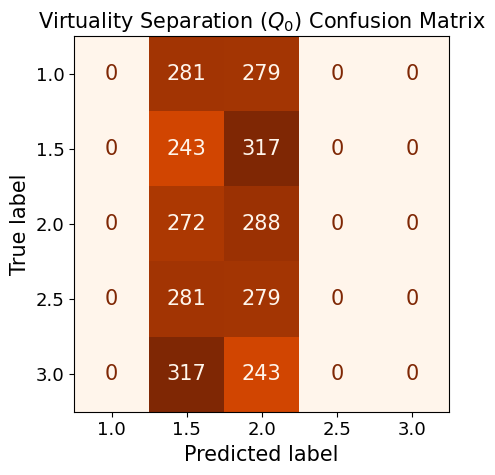

In [19]:
plot_confusion_matrices(best_metrics, output_dir= f"{cfg.output_dir}/val", color_map="Oranges")

In [20]:
alpha_names = ("0.2","0.25","0.3","0.35","0.4","0.45","0.5")
q0_names    = ("1.0","1.5","2.0","2.5","3.0")


Saved images:
  α_s histogram:         experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/val/prob_plots/alpha_pred_hist
  α_s avg-prob bars:     experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/val/prob_plots/alpha_avgprob.png
  α_s probabilities:      experiments/exp_02_transfer_learning_with_vit_backbone/training_output/vit_legacy_branch_1b_lrp_12_rlrp_4_bs32_ep1_lr1e-04_ds14000_g1_sched_ReduceLROnPlateau_preloaded_weighted_lossenergy_loss_output_1.0_alpha_output_1.0_q0_output_1.0/fold_0/val/prob_plots/alpha_pred_hist_probs.csv
  α_s heatmap:           experiments/exp_02_transfer_learning_with_vit_backbone

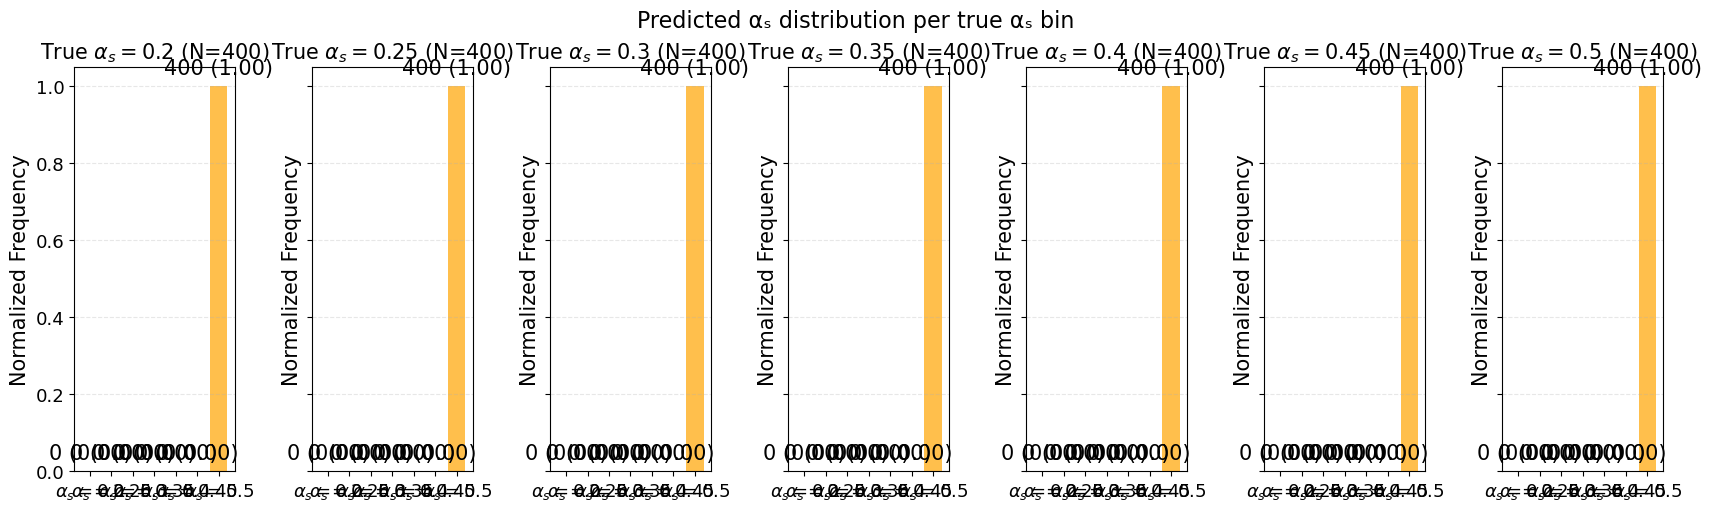

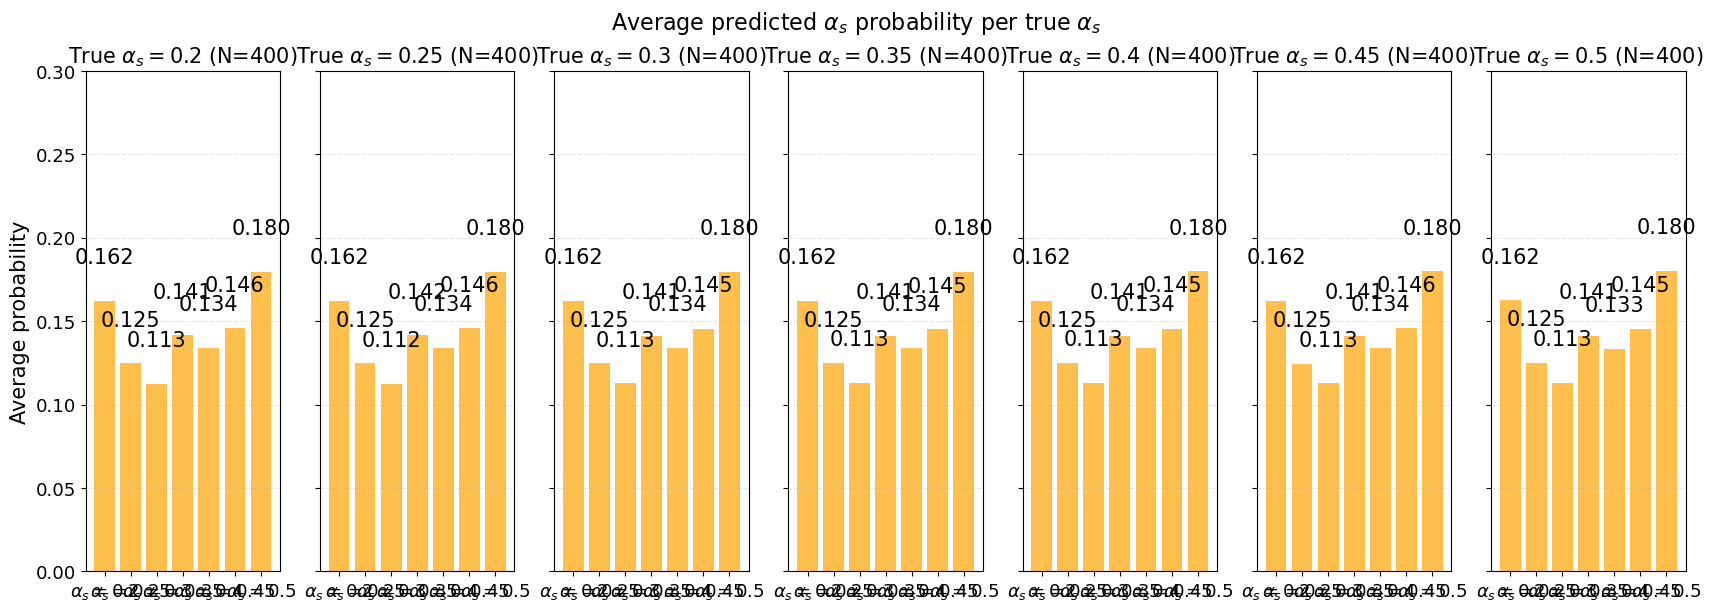

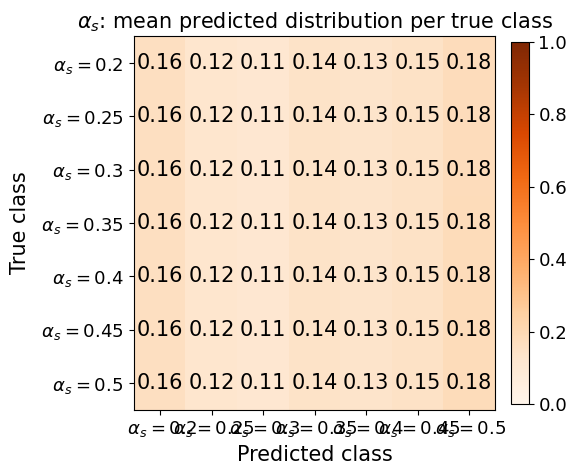

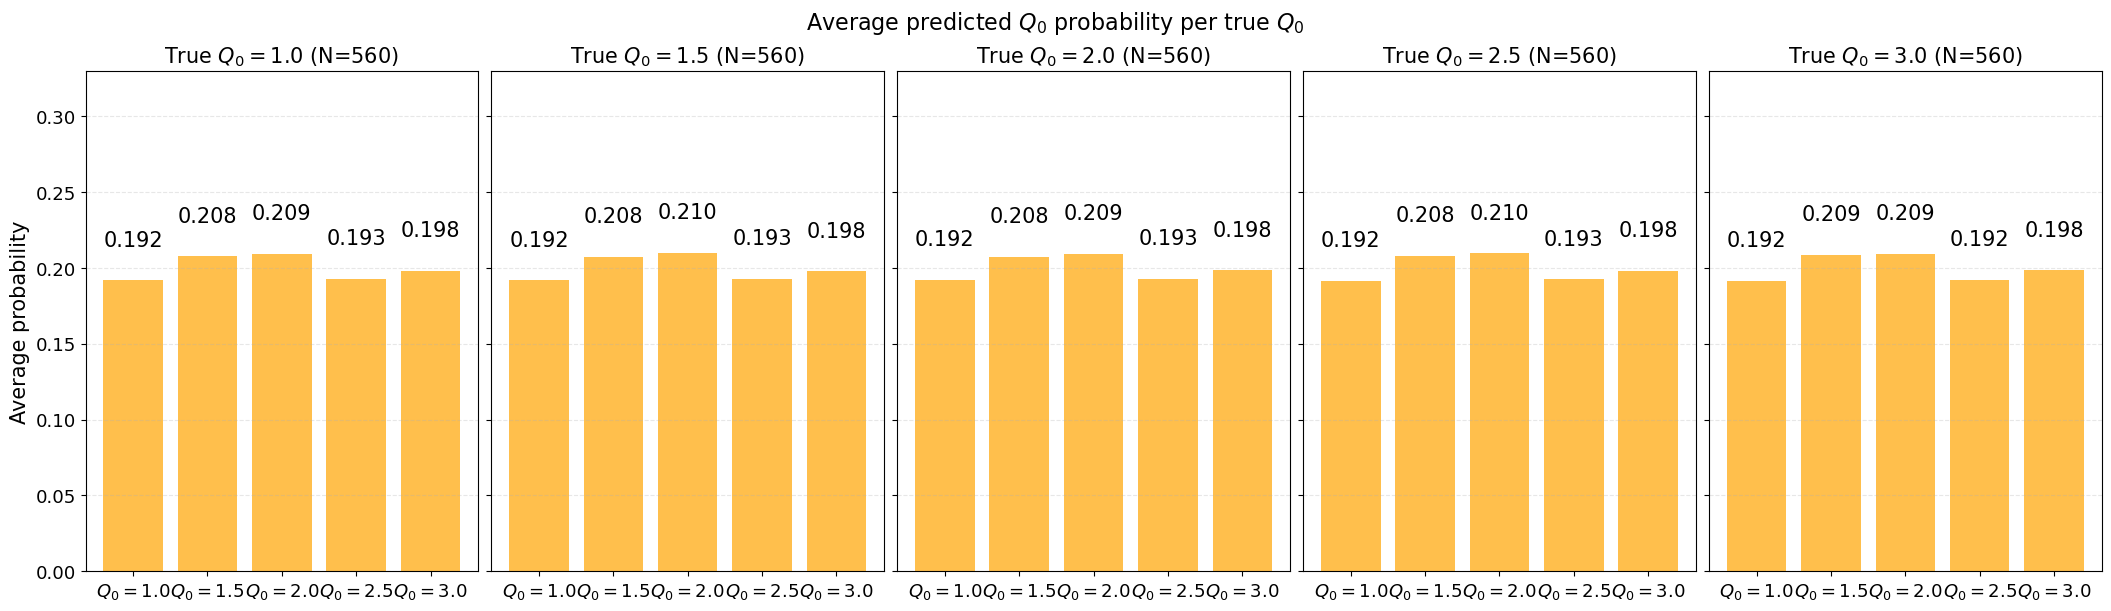

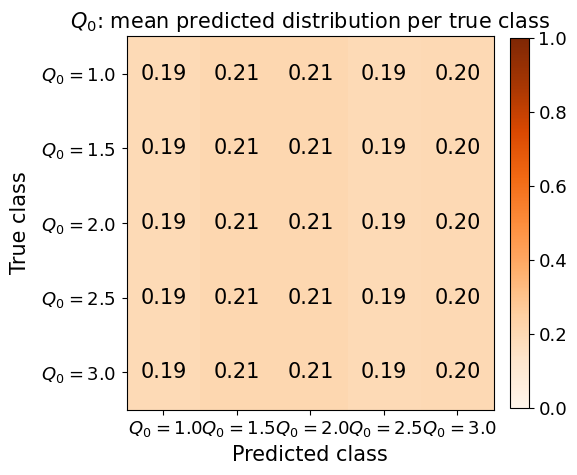

In [21]:
from train_utils.evaluate import evaluate
# experiment folder for artifacts
art_dir = os.path.join(cfg.output_dir,"val/prob_plots")
os.makedirs(art_dir, exist_ok=True)

alpha_hist_path      = os.path.join(art_dir, "alpha_pred_hist")      # .png/.pdf added by evaluate
alpha_avgprob_path   = os.path.join(art_dir, "alpha_avgprob")        # .png/.pdf added by evaluate
q0_avgprob_path      = os.path.join(art_dir, "q0_avgprob")           # .png/.pdf added by evaluate

metrics_val = evaluate(
    val_loader, model, criterion, device,
    loss_weights=getattr(cfg, "loss_weights", None),
    # plots:
    make_alpha_fig=True,
    alpha_fig_path=str(alpha_hist_path),
    make_alpha_avgprob_fig=True,
    alpha_avgprob_fig_path=str(alpha_avgprob_path),
    make_q0_avgprob_fig=True,
    q0_avgprob_fig_path=str(q0_avgprob_path),
    alpha_class_names=alpha_names,
    q0_class_names=q0_names,
)

print("Saved images:")
print("  α_s histogram:        ", metrics_val.get("alpha_hist_path"))
print("  α_s avg-prob bars:    ", metrics_val.get("alpha_avgprob_hist_path"))
print("  α_s probabilities:     ", metrics_val.get("alpha_probs_csv"))
print("  α_s heatmap:          ", metrics_val.get("alpha_heatmap_path"))
print("  Q0  avg-prob bars:    ", metrics_val.get("q0_avgprob_hist_path"))
print("  Q0  probabilities:     ", metrics_val.get("q0_probs_csv"))
print("  Q0  heatmap:          ", metrics_val.get("q0_heatmap_path"))


In [ ]:
# (optional) test split as well
# try:
#     from train_utils.evaluate import evaluate
#     # experiment folder for artifacts
#     art_dir = os.path.join(cfg.output_dir,"test/prob_plots")
#     os.makedirs(art_dir, exist_ok=True)

#     alpha_hist_path      = os.path.join(art_dir, "alpha_pred_hist")      # .png/.pdf added by evaluate
#     alpha_avgprob_path   = os.path.join(art_dir, "alpha_avgprob")        # .png/.pdf added by evaluate
#     q0_avgprob_path      = os.path.join(art_dir, "q0_avgprob")           # .png/.pdf added by evaluate

#     metrics_test = evaluate(
#         test_loader, model, criterion, device,
#         loss_weights=getattr(cfg, "loss_weights", None),
#         # plots:
#         make_alpha_fig=True,
#         alpha_fig_path=str(alpha_hist_path),
#         make_alpha_avgprob_fig=True,
#         alpha_avgprob_fig_path=str(alpha_avgprob_path),
#         make_q0_avgprob_fig=True,
#         q0_avgprob_fig_path=str(q0_avgprob_path),
#         alpha_class_names=alpha_names,
#         q0_class_names=q0_names,
#     )

#     print("Saved images:")
#     print("  α_s histogram:        ", metrics_test.get("alpha_hist_path"))
#     print("  α_s avg-prob bars:    ", metrics_test.get("alpha_avgprob_hist_path"))
#     print("  α_s probabilities:     ", metrics_test.get("alpha_probs_csv"))
#     print("  α_s heatmap:          ", metrics_test.get("alpha_heatmap_path"))
#     print("  Q0  avg-prob bars:    ", metrics_test.get("q0_avgprob_hist_path"))
#     print("  Q0  probabilities:     ", metrics_test.get("q0_probs_csv"))
#     print("  Q0  heatmap:          ", metrics_test.get("q0_heatmap_path"))
#     have_test = True
# except NameError:
#     have_test = False